<a href="https://colab.research.google.com/github/barisaykent-spec/Veri_Muh_Proje1/blob/main/calisma/baris/BIL545_Proje1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize notu** · Teslim ve sunum: **8. hafta**

Bu defter projenin şablonudur. Grubunuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje1/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi
| | Ad Soyad | Öğrenci no |
|---|---|---|
| Üye 1 | | |
| Üye 2 *(varsa)* | | |
| Üye 3 *(varsa)* | | |
| Üye 4 *(varsa)* | | |
| Üye 5 *(varsa)* | | |

**Grup adı:**  
**GitHub deposu:** https://github.com/barisaykent-spec/Veri_Muh_Proje1  
**Veri kümesi ve sorumuz (tek cümle):**

## Hazırlık

In [2]:
import sys, numpy as np, pandas as pd, sklearn
SEED = 42
np.random.seed(SEED)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)

Python       3.13.18
numpy        2.1.3
pandas       2.2.3
scikit-learn 1.6.1


### Veriyi yükleme
**Kaynak:** Inside Airbnb (http://insideairbnb.com/get-the-data/) · İstanbul, Marmara, Türkiye · `listings.csv.gz` (detaylı ilan dosyası, ≈75 sütun) · anlık görüntü tarihi: `SNAPSHOT` değişkeninde.  
**Lisans:** Creative Commons Attribution 4.0 International (CC BY 4.0).  
**İndirme / yükleme adımı:** Hücre önce çalışma klasöründe `listings.csv.gz` arar; yoksa dosyayı Inside Airbnb sunucusundan indirir. Sunucuda o tarih artık yoksa, grubun sakladığı kopyayı Colab'a yükleyin (sol menü → Dosyalar → Yükle). Veri depoya konmaz.

In [3]:
import os

SNAPSHOT = "2026-09-25"   # Inside Airbnb sayfasındaki İstanbul anlık görüntü tarihi; dönem boyunca sabit
URL   = f"https://data.insideairbnb.com/turkey/marmara/istanbul/{SNAPSHOT}/data/listings.csv.gz"
LOCAL = "listings.csv.gz"

if not os.path.exists(LOCAL):
    import urllib.request
    urllib.request.urlretrieve(URL, LOCAL)

df = pd.read_csv(LOCAL, low_memory=False)
print("Anlık görüntü:", SNAPSHOT, "| boyut:", df.shape)
df.head(3)

Anlık görüntü: 2026-09-25 | boyut: (27232, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,25436,https://www.airbnb.com/rooms/25436,20260925130056,2026-09-28,previous scrape,In the forest Sea view Two minutes to the city.,Our house is in Bebek Koru. If you want villag...,NaN,https://a0.muscache.com/pictures/b64c3ef0-2256...,105823,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,34177,https://www.airbnb.com/rooms/34177,20260925130056,2026-09-28,previous scrape,PETIT HOUSE,My petit house is located in the bosphorous an...,NaN,https://a0.muscache.com/pictures/47356451/c288...,147330,...,4.81,4.69,4.81,NaN,NaN,2,2,0,0,0.12
2,42835,https://www.airbnb.com/rooms/42835,20260925130056,2026-09-28,previous scrape,Cozy apartment in the heart of Istanbul,Welcome to our cozy 2-bedroom apartment locate...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,187026,...,NaN,NaN,NaN,NaN,NaN,3,1,2,0,NaN


In [4]:
df.shape

(27232, 90)

In [5]:
df.dtypes.value_counts()

,count
float64,31
int64,30
object,29


In [6]:
df.columns.tolist()

['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'neighborhood_overview',
 'picture_url',
 'host_id',
 'host_url',
 'host_profile_id',
 'host_profile_url',
 'host_name',
 'host_since',
 'hosts_time_as_user_years',
 'hosts_time_as_user_months',
 'hosts_time_as_host_years',
 'hosts_time_as_host_months',
 'host_location',
 'host_about',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_is_superhost',
 'host_thumbnail_url',
 'host_picture_url',
 'host_neighbourhood',
 'host_listings_count',
 'host_total_listings_count',
 'host_verifications',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'price_quote_checkin_date',
 'price_quote_checkout_date',
 'price_quote_total_price',
 'price_quote

In [7]:
print(df.loc[0, "description"])

Our house is in Bebek Koru. If you want village life in the city, you are in the right place, and the beach, Centrum shopping cafe bar are within a 3-minute walk.  A place with a unique nature and sea view where you can wake up with the sounds of birds, away from the traffic horns.  There are two entrances and a parking lot on the lower side. 2+1 living room


In [8]:
df[["price", "bathrooms_text", "host_is_superhost", "amenities"]].head()

,price,bathrooms_text,host_is_superhost,amenities
0,NaN,1 bath,f,"[""Coffee"", ""Backyard"", ""Hot water"", ""Wifi"", ""D..."
1,"$4,736.32",1 bath,f,"[""Hot water"", ""Wifi"", ""Dishes and silverware"",..."
2,NaN,2 baths,f,"[""Hot water"", ""Ceiling fan"", ""Wifi"", ""Dishes a..."
3,"$1,501.51",1 bath,f,"[""Hot water"", ""Free washer \u2013 In unit"", ""W..."
4,"$11,860.00",1 bath,f,"[""Hot water"", ""Wifi"", ""Stove"", ""Kitchen"", ""Was..."


In [9]:
df[["price", "bathrooms_text", "host_is_superhost", "amenities"]]

,price,bathrooms_text,host_is_superhost,amenities
0,NaN,1 bath,f,"[""Coffee"", ""Backyard"", ""Hot water"", ""Wifi"", ""D..."
1,"$4,736.32",1 bath,f,"[""Hot water"", ""Wifi"", ""Dishes and silverware"",..."
2,NaN,2 baths,f,"[""Hot water"", ""Ceiling fan"", ""Wifi"", ""Dishes a..."
3,"$1,501.51",1 bath,f,"[""Hot water"", ""Free washer \u2013 In unit"", ""W..."
4,"$11,860.00",1 bath,f,"[""Hot water"", ""Wifi"", ""Stove"", ""Kitchen"", ""Was..."
...,...,...,...,...
27227,"$7,301.00",1 bath,f,"[""Washer"", ""TV"", ""Wifi"", ""First aid kit"", ""Pet..."
27228,"$8,360.00",1.5 baths,f,"[""Washer"", ""Wifi"", ""First aid kit"", ""Pets allo..."
27229,"$2,560.00",1 bath,f,"[""Heating"", ""Hot water"", ""TV"", ""Air conditioni..."
27230,"$2,140.02",1 private bath,f,"[""Heating"", ""Cooking basics"", ""Hot water"", ""TV..."


In [10]:
df["host_since"].isna().mean()
df[["id", "host_id","price"]].head()

,id,host_id,price
0,25436,105823,NaN
1,34177,147330,"$4,736.32"
2,42835,187026,NaN
3,73477,383789,"$1,501.51"
4,77292,414003,"$11,860.00"


**Price sutunu sayı olarak değil text olarak görünüyor. dolar ifadesi bunu engelliyor. ayrıca rakamlar dolar değil TL**

In [11]:
df["host_is_superhost"].value_counts()

,count
host_is_superhost,
f,21257
t,5975


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu (3–4 cümle):** …

### 1.1 Veri künyesi
| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? | **Inside Airbnb**: Murray Cox'un 2014'te başlattığı, 2023'ten beri kâr amacı gütmeyen Housing Justice Data Lab ile birlikte sürdürülen bağımsız bir izleme (watchdog) projesi. Amacı Airbnb'nin konut piyasası ve mahalleler üzerindeki etkisini (yasa dışı kiralama, soylulaştırma, konut stokunun turizme kayması) görünür kılmak. Veri, Airbnb sitesindeki **herkese açık ilan sayfalarından kazıma (scraping)** ile toplanıyor; Airbnb'nin resmî verisi değil, Airbnb doğruluğuna itiraz ediyor. Toplayanın bir **savunuculuk amacı** var; bu, hangi sütunların toplandığını ve nasıl türetildiğini (ör. `estimated_occupancy_l365d`, `estimated_revenue_l365d` bir modelin tahminleridir) etkiler. |
| Hangi dönemi kapsıyor? | Tek bir **kesit**: kazıma 2026-09-25'te başlatılmış (`scrape_id`), ilanlar 28–29 Eylül 2026'da okunmuş (`last_scraped`). Zaman serisi değil. Yorum tarihleri 2011-05-17'ye kadar uzansa da bunlar ilanın geçmişidir, verinin kapsadığı dönem değildir. Türetilmiş sütunlar (`*_ltm`, `*_l365d`, `*_l30d`) kazıma anına göre geriye dönük pencereler. |
| Hedef gerçek olgu mu, vekil mi? | **Vekil.** Hedef (gecelik fiyat dilimi), gerçekleşmiş bir kiralama bedeli değil, Inside Airbnb'nin kazıma anında belirli bir giriş-çıkış tarihi için aldığı **teklif fiyatı** (`price` = `price_quote_price_per_night`, teklif süresi %95 oranında `minimum_nights`'a eşit). Teklif tarihine (sezon, hafta sonu), uzun konaklama indirimlerine ve ev sahibinin anlık fiyatlamasına bağlı. Para birimi alanı boş; değerlerin büyüklüğü **TL** olduğunu düşündürüyor (medyan ≈ 3.710), bu bir çıkarımdır. |
| Kimlerin eksik temsil ediliyor olabileceği? | (1) **Takvimi kapalı ilanlar**: teklif alınamadığı için fiyatı yok (%9,8), analizden düşüyor. (2) **Uzun dönem ilanlar**: 7464 sayılı Kanun (1 Ocak 2024) 100 güne kadar konaklamaları izne bağladığı için ilanların %36,4'ü en az 100 geceye geçmiş; kapsam kararıyla (`minimum_nights < 30`) bilerek dışarıda. (3) **Airbnb dışı platformlar** (Booking, yerel siteler) ve **kayıt dışı** kiralamalar hiç yok. (4) Kanun özel odaların kısa dönem kiralanmasını yasaklıyor; buna rağmen kısa dönem ilanların %26,6'sı özel oda. Yani veri **kurala uymayanları da** içeriyor, ama uyumla ilgili cevap verenler ve vermeyenler aynı biçimde temsil edilmiyor olabilir. (5) Yeni ve yorumsuz ilanlar (%35,5'inin hiç yorumu yok): puan sütunları bu grupta boş. |
| Lisans | **CC BY 4.0** (Creative Commons Attribution 4.0 International). Kopyalama, değiştirme ve yeniden paylaşım serbest; **kaynak (Inside Airbnb) ve anlık görüntü tarihi belirtilmek zorunda**. Bu yüzden veri depoya konmaz, ama künyede ve README'de kaynak açıkça gösterilir. |

In [12]:
# 1.1'deki iddiaları destekleyen sayılar
print("Kazıma kimliği       :", df["scrape_id"].unique())
print("Okunma tarihleri     :", df["last_scraped"].min(), "→", df["last_scraped"].max())

# Hata veren satırı tarih dönüşümü yaparak çözüyoruz
ilk_yorum = pd.to_datetime(df["first_review"])
son_yorum = pd.to_datetime(df["last_review"])
print("İlk / son yorum      :", ilk_yorum.min(), "→", son_yorum.max())

fiyat = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)
gece  = (pd.to_datetime(df["price_quote_checkout_date"]) - pd.to_datetime(df["price_quote_checkin_date"])).dt.days
print("price = teklif gecelik fiyatı mı? :", np.allclose(fiyat.dropna(), df["price_quote_price_per_night"].dropna()))
print("Teklif süresi = minimum_nights    :", round((gece == df["minimum_nights"].clip(upper=365))[gece.notna()].mean(), 3))
print("Fiyatı boş ilan oranı             :", round(fiyat.isna().mean(), 3))
print("Medyan gecelik fiyat              :", fiyat.median())

kisa = df["minimum_nights"] < 30
print("minimum_nights >= 100 oranı       :", round((df["minimum_nights"] >= 100).mean(), 3))
print("Kısa dönemde özel oda oranı       :", round((df.loc[kisa, "room_type"] == "Private room").mean(), 3))
print("Hiç yorumu olmayan ilan oranı     :", round((df["number_of_reviews"] == 0).mean(), 3))

Kazıma kimliği       : [20260925130056]
Okunma tarihleri     : 2026-09-28 → 2026-09-29
İlk / son yorum      : 2011-05-17 00:00:00 → 2026-09-28 00:00:00
price = teklif gecelik fiyatı mı? : True
Teklif süresi = minimum_nights    : 0.951
Fiyatı boş ilan oranı             : 0.098
Medyan gecelik fiyat              : 3710.0
minimum_nights >= 100 oranı       : 0.364
Kısa dönemde özel oda oranı       : 0.266
Hiç yorumu olmayan ilan oranı     : 0.355


**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

**Ne bulduk:** Veri, savunuculuk amaçlı bir projenin tek bir haftasonu yaptığı kazımanın kesiti. Hedefimiz olan fiyat ise ölçülmüş bir işlem bedeli değil, belirli tarihler için alınmış bir teklif.

**Bu ne anlama geliyor:**
- Modelimizin öğrenebileceği şey, *"bir ilanın Eylül 2026 sonunda verdiği teklif hangi dilimde?"* sorusudur; *"bu evin gerçek gecelik değeri"* değil. Sınıf sınırları (3.455,50 / 5.877,67) bu kesite özgü. Mevsim ve kur değiştiğinde sınırlar kayar; model başka bir anlık görüntüye doğrudan taşınamaz.
- 7464 sayılı Kanun, verinin şeklini değiştirmiş bir dış müdahale. 100 gecedeki yığılma ve `license` sütunundaki izin numaraları bunun izi. Bu yüzden 2024 öncesi anlık görüntülerle yapılacak bir karşılaştırma aynı pazarı ölçmez.
- Eksik temsil edilen gruplar (takvimi kapalı ilanlar, kayıt dışı kiralama) rastgele değil. Sonuçlarımız *"Airbnb'de fiyatı görünen kısa dönem İstanbul ilanları"* için geçerli, *"İstanbul'daki kısa dönem kiralama pazarı"* için değil.

**Neyi söyleyemeyiz:** Fiyatın gerçekleşip gerçekleşmediğini (rezervasyon bilgisi yok), para biriminin kesin olarak TL olduğunu ve ilanların yasal uyumunu bu veriyle söyleyemeyiz. `license` sütununda açıkça sahte değerler var (`12-3456` 103 kez geçiyor; tek bir izin numarası 182 ilanda kullanılmış). Bu konu 1.2'deki şüpheli öznitelikler listesine aktarılıyor.

### 1.2 Keşifsel analiz
Boyut; saklama ve ölçek tipleri; hedef dağılımı; yinelenen satırlar; künye tablosu (tip, eksik oranı, farklı değer sayısı, sıfır oranı); şüpheli öznitelik listesi.

In [13]:
df.dtypes.value_counts()

,count
float64,31
int64,30
object,29


In [14]:
import pandas as pd
# Sütun sınırını kaldırarak tüm sütunların gösterilmesini sağlıyoruz
pd.set_option('display.max_columns', None)

# Şimdi tüm kolonları görmek için tekrar yazdırabilirsiniz:
display(df.head(3))

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,25436,https://www.airbnb.com/rooms/25436,20260925130056,2026-09-28,previous scrape,In the forest Sea view Two minutes to the city.,Our house is in Bebek Koru. If you want villag...,NaN,https://a0.muscache.com/pictures/b64c3ef0-2256...,105823,https://www.airbnb.com/users/show/105823,1462509707466640732,https://www.airbnb.com/users/profile/146250970...,Yesim,NaN,16,5,15,8,"İstanbul, Turkey","Merhabalar . Kuş sesi , akan su sesi ile uyan...",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/067a8...,NaN,1,NaN,NaN,t,t,NaN,Besiktas,NaN,41.07883,29.03863,Entire rental unit,Entire home/apt,3,NaN,1 bath,2.0,4.0,"[""Coffee"", ""Backyard"", ""Hot water"", ""Wifi"", ""D...",NaN,NaN,NaN,NaN,NaN,NaN,100,160,100,100,160,160,100.0,160.0,NaN,t,0,0,0,0,2026-09-28,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,34177,https://www.airbnb.com/rooms/34177,20260925130056,2026-09-28,previous scrape,PETIT HOUSE,My petit house is located in the bosphorous an...,NaN,https://a0.muscache.com/pictures/47356451/c288...,147330,https://www.airbnb.com/users/show/147330,1462510899379737925,https://www.airbnb.com/users/profile/146251089...,Ercan,NaN,16,3,15,8,"Istanbul, Turkey",grounded and well-traveled interior architect,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/147330/profil...,NaN,2,NaN,NaN,t,t,NaN,Besiktas,NaN,41.06681,29.04035,Entire home,Entire home/apt,3,NaN,1 bath,1.0,2.0,"[""Hot water"", ""Wifi"", ""Dishes and silverware"",...","$4,736.32",2026-09-29,2027-01-07,473632.37,4736.32,"{""quote"": {""taxes"": null, ""currency"": null, ""d...",100,365,100,100,365,365,100.0,365.0,NaN,t,29,59,89,364,2026-09-28,16,0,0,94,0,0,0.0,2015-12-29,2024-01-03,4.69,4.69,4.88,4.88,4.81,4.69,4.81,NaN,NaN,2,2,0,0,0.12
2,42835,https://www.airbnb.com/rooms/42835,20260925130056,2026-09-28,previous scrape,Cozy apartment in the heart of Istanbul,Welcome to our cozy 2-bedroom apartment locate...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,187026,https://www.airbnb.com/users/show/187026,1462512109122697564,https://www.airbnb.com/users/profile/146251210...,Attila,NaN,16,1,15,8,"Istanbul, Turkey",I am from Istanbul/ Turkey. I will do my best ...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/187026/profil...,NaN,3,NaN,NaN,t,t,NaN,Sisli,NaN,41.04303,28.98531,Entire rental unit,Entire home/ap

In [15]:
import pandas as pd
# Sınırları kaldırıyoruz
pd.set_option('display.max_rows', None)

# Oranları hesaplayıp her satırı tek tek yazdırarak truncation (kırpılma) sorununu çözüyoruz
missing_ratios = df.isna().mean()
for col, val in missing_ratios.items():
    print(f"{col:<50} {val:.6f}")

id                                                 0.000000
listing_url                                        0.000000
scrape_id                                          0.000000
last_scraped                                       0.000000
source                                             0.608218
name                                               0.000000
description                                        0.005949
neighborhood_overview                              1.000000
picture_url                                        0.000000
host_id                                            0.000000
host_url                                           0.000000
host_profile_id                                    0.000000
host_profile_url                                   0.000000
host_name                                          0.000000
host_since                                         1.000000
hosts_time_as_user_years                           0.000000
hosts_time_as_user_months               

**Yorum** Sıfır demek, hiç eksik kayıt yok tamamen dolu demek. 1 e yaklaştıkça yüzde kaç boş olduğunu göstermektedir. Örneğin; neighborhood_overview değeri 1 yani içi boş. yani hiç komşuluk bilgisi yok.

…

In [16]:
df.nunique()

,0
id,27232
listing_url,27232
scrape_id,1
last_scraped,2
source,1
name,25571
description,17410
neighborhood_overview,0
picture_url,25806
host_id,9967


**yorum** Verinin kaliteli olduğunu düşünüyorum. Çünkü; kolonlarda çok fazla farklı değer var. birbirlerinin kopyası değiller. Detaylı analize imkan verecek yapıda. Ama bazı kolonlarda veri Sıfır farklı değer içeriyor. Bu kolonları çıkarabiliriz. Sonucu etkilemeyecektir.

### 1.3 Eksiklik analizi
Eksik kodlarını `NaN`'a çevirin; deseni görselleştirin; en çok eksiği olan iki sütun için MCAR / MAR / MNAR tahmini; `add_indicator` etkisi.

In [17]:
# ===== 1.3-a: Kodlanmış eksikleri ara =====
# Fikir: "boş" görünmeyen ama "bilinmiyor / geçersiz" anlamına gelebilecek değerleri bul.

# 1) Sayısal sütunlarda sıfır oranı — sıfır bazen gerçek, bazen "bilinmiyor" demek
sayisal = df.select_dtypes("number")
sifir_orani = (sayisal == 0).mean().sort_values(ascending=False)
print("--- Sıfır oranı > 0 olan sayısal sütunlar ---")
print((sifir_orani[sifir_orani > 0] * 100).round(1).to_string())

# 2) Mantıksız değer: puanlar 1–5 arasında olmalı
print("\n--- Puanı 1'in altında olan ilan sayısı ---")
print((df["review_scores_rating"] < 1).sum())

# 3) Aynı değerin çok sık tekrarı — bir 'varsayılan' değer olabilir
print("\n--- maximum_nights en sık 5 değer ---")
print(df["maximum_nights"].value_counts().head(5))

# 4) Metin sütunlarında yer tutucu (placeholder) değerler
print("\n--- license en sık 8 değer ---")
print(df["license"].value_counts().head(8))

# 5) Boş değerin bir anlamı var mı? (önceki adımda konuştuğumuz has_availability)
print("\n--- has_availability boş mu? x fiyat boş mu? ---")
print(pd.crosstab(df["has_availability"].fillna("BOŞ"), df["price"].isna()))

--- Sıfır oranı > 0 olan sayısal sütunlar ---
calculated_host_listings_count_shared_rooms     98.1
number_of_reviews_l30d                          74.2
number_of_reviews_ly                            65.0
calculated_host_listings_count_private_rooms    58.9
estimated_occupancy_l365d                       55.0
number_of_reviews_ltm                           55.0
estimated_revenue_l365d                         46.3
number_of_reviews                               35.5
calculated_host_listings_count_entire_homes     25.2
hosts_time_as_user_months                       12.3
availability_30                                 10.2
hosts_time_as_host_months                        9.5
hosts_time_as_host_years                         9.5
availability_60                                  8.5
availability_90                                  7.6
availability_eoy                                 7.4
hosts_time_as_user_years                         7.3
bedrooms                                         3.8


In [18]:
# ===== 1.3-a — Kodlanmış eksikleri NaN'a (ya da doğru anlamına) çevirme =====
# Bu dönüşümler veriden bir şey ÖĞRENMEZ (satır satır kural uygular),
# bu yüzden bölmeden önce bütün veride yapılması sızıntı yaratmaz.
import numpy as np

df13 = df.copy()          # ham df'yi bozmamak için kopya üzerinde çalışıyoruz
once = df13.isna().sum()  # dönüşümden önceki eksik sayıları (karşılaştırma için)

# 1) license = "12-3456" -> NaN  (103 ilanda aynı sahte numara: yer tutucu)
#    "Non-real estate listing" ve "Exempt" GERÇEK kategorilerdir, dokunmuyoruz.
df13.loc[df13["license"] == "12-3456", "license"] = np.nan

# 2) review_scores_rating < 1 -> NaN  (ölçek 1–5; satırı değil sadece hatalı hücreyi boşaltıyoruz)
df13.loc[df13["review_scores_rating"] < 1, "review_scores_rating"] = np.nan

# 3) has_availability boş -> "f"  (boş = "müsait değil"; ters yönlü kodlama)
df13["has_availability"] = df13["has_availability"].fillna("f")

# DOKUNMADIKLARIMIZ:
#   bedrooms = 0          -> stüdyo / ortak oda: geçerli sıfır
#   number_of_reviews = 0 -> yeni ilan: geçerli sıfır
#   maximum_nights = 365 / 1125 -> platform varsayılanı; eksik değil, not ediyoruz

sonra = df13.isna().sum()
degisen = (sonra - once)
print("Eksik sayısı değişen sütunlar:")
print(degisen[degisen != 0].to_string())
print("\nhas_availability değerleri:", df13["has_availability"].value_counts().to_dict())

Eksik sayısı değişen sütunlar:
has_availability       -457
review_scores_rating      1
license                 103

has_availability değerleri: {'t': 26775, 'f': 457}


Ne bulduk: Üç kodlanmış eksik tespit edildi. license sütununda 103 ilanda tekrar eden “12-3456” sahte bir yer tutucudur, NaN’a çevrildi. review_scores_rating’de 1–5 ölçeği dışında kalan bir 0 değeri NaN yapıldı. has_availability’deki boşluklar ise “bilinmiyor” değil “müsait değil” anlamındadır (boşların 447/457'sinde fiyat da yok), “f” ile dolduruldu. bedrooms = 0 (stüdyo) ve number_of_reviews = 0 (yeni ilan) geçerli sıfırlar olarak bırakıldı.

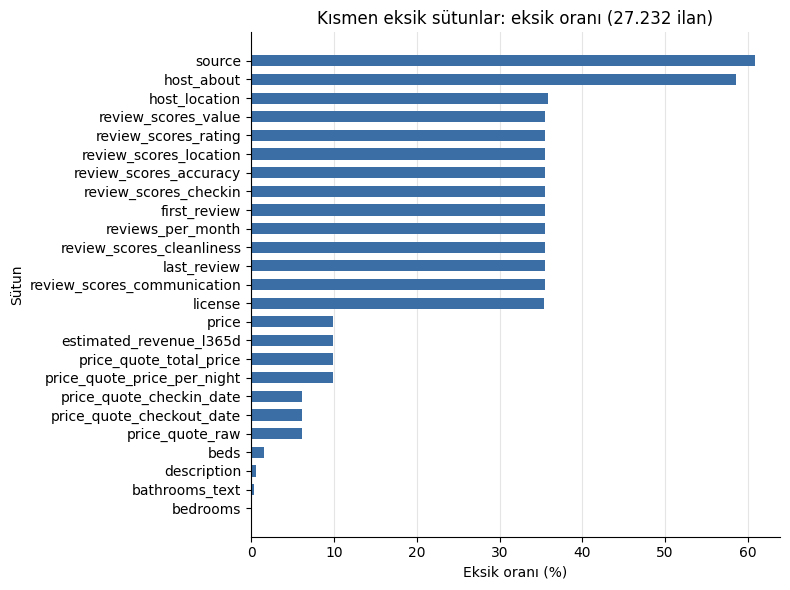

Açıklama: Puan sütunlarının hepsi aynı oranda (%35,5) eksik; fiyat ve fiyattan türeyen sütunlar da kendi aralarında aynı oranda (%9,8) eksik.


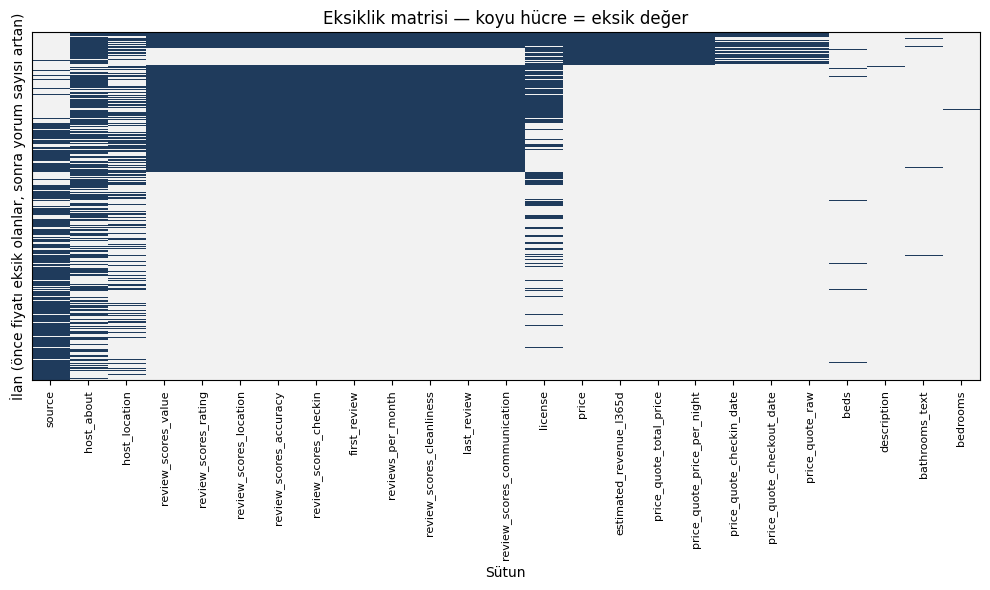

Açıklama: Puan sütunları aynı satırlarda birlikte eksik, fiyat sütunları da ayrı bir blok halinde birlikte eksik.

Puan eksik olan ilanlarda number_of_reviews = 0 oranı: 1.0
Puan dolu olan ilanlarda number_of_reviews = 0 oranı: 0.0


In [19]:
# ===== 1.3-b — Eksiklik desenini görselleştirme =====
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Kısmen eksik olan sütunlar (tamamen boş ya da tamamen dolu olanlar desen göstermez)
eksik = df13.isna().mean()
kismi = eksik[(eksik > 0) & (eksik < 1)].sort_values(ascending=False)

# ---- Grafik 1: Sütun başına eksik oranı ----
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(kismi.index[::-1], kismi.values[::-1] * 100, color="#3b6ea5", height=0.6)
ax.set_xlabel("Eksik oranı (%)")
ax.set_ylabel("Sütun")
ax.set_title("Kısmen eksik sütunlar: eksik oranı (27.232 ilan)")
ax.grid(axis="x", color="#e5e5e5"); ax.set_axisbelow(True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print("Açıklama: Puan sütunlarının hepsi aynı oranda (%35,5) eksik; fiyat ve fiyattan türeyen "
      "sütunlar da kendi aralarında aynı oranda (%9,8) eksik.")

# ---- Grafik 2: Eksiklik matrisi (her satır bir ilan, koyu = eksik) ----
# Satırları anlamlı bir sırayla diziyoruz: önce fiyatı eksik olanlar, sonra yorum sayısına göre.
# Böylece "birlikte eksik olan" sütunlar bloklar halinde görünür.
sirali = (df13.assign(_fiyat_yok=df13["price"].isna())
               .sort_values(["_fiyat_yok", "number_of_reviews"], ascending=[False, True]))
ornek = sirali.iloc[::10]                       # her 10 ilandan biri: ~2.700 satır, okunaklı
matris = ornek[kismi.index].isna().to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(matris, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#f2f2f2", "#1f3b5c"]))   # açık = dolu, koyu = eksik
ax.set_xticks(range(len(kismi)))
ax.set_xticklabels(kismi.index, rotation=90, fontsize=8)
ax.set_xlabel("Sütun")
ax.set_ylabel("İlan (önce fiyatı eksik olanlar, sonra yorum sayısı artan)")
ax.set_title("Eksiklik matrisi — koyu hücre = eksik değer")
ax.set_yticks([])
plt.tight_layout(); plt.show()
print("Açıklama: Puan sütunları aynı satırlarda birlikte eksik, "
      "fiyat sütunları da ayrı bir blok halinde birlikte eksik.")

# ---- Sayısal kanıt: puanların eksik olduğu satırlarda yorum sayısı kaç? ----
puan_yok = df13["review_scores_accuracy"].isna()
print("\nPuan eksik olan ilanlarda number_of_reviews = 0 oranı:",
      round((df13.loc[puan_yok, "number_of_reviews"] == 0).mean(), 3))
print("Puan dolu olan ilanlarda number_of_reviews = 0 oranı:",
      round((df13.loc[~puan_yok, "number_of_reviews"] == 0).mean(), 3))

In [20]:
# =====================================================================
# 1.3-b (devam) — Grafikte gördüğümüzü "select" mantığıyla doğrulama
# SQL karşılığı:  SELECT grup, AVG(sutun IS NULL) FROM df13 GROUP BY grup
# pandas'ta:      df13["sutun"].isna().groupby(grup).mean()
# =====================================================================
import numpy as np

yorum_grubu = pd.cut(df13["number_of_reviews"], [-1, 0, 5, 30, 10_000],
                     labels=["0", "1-5", "6-30", "30+"])
gece_grubu  = np.where(df13["minimum_nights"] >= 100, "100+ gece", "100'den az")

def eksik_orani_gruba_gore(sutun, grup, grup_adi):
    tablo = (df13[sutun].isna().groupby(grup, observed=True).mean() * 100).round(1)
    print(f"{sutun:<22} eksik % | {grup_adi}: {tablo.to_dict()}")

print("--- Blok 1: puan sütunları ---")
eksik_orani_gruba_gore("review_scores_rating", yorum_grubu, "yorum sayısı")

print("\n--- Blok 2: fiyat sütunları ---")
eksik_orani_gruba_gore("price", df13["availability_365"] == 0, "takvim tamamen kapalı mı")
eksik_orani_gruba_gore("price", gece_grubu, "en az konaklama")

print("\n--- license ---")
eksik_orani_gruba_gore("license", gece_grubu, "en az konaklama")

print("\n--- Dağınık görünenler: host_about, host_location ---")
eksik_orani_gruba_gore("host_about", yorum_grubu, "yorum sayısı")
eksik_orani_gruba_gore("host_about", df13["host_is_superhost"], "süper ev sahibi")
eksik_orani_gruba_gore("host_location", yorum_grubu, "yorum sayısı")

--- Blok 1: puan sütunları ---
review_scores_rating   eksik % | yorum sayısı: {'0': 100.0, '1-5': 0.0, '6-30': 0.0, '30+': 0.0}

--- Blok 2: fiyat sütunları ---
price                  eksik % | takvim tamamen kapalı mı: {False: 7.1, True: 99.8}
price                  eksik % | en az konaklama: {"100'den az": 3.4, '100+ gece': 21.1}

--- license ---
license                eksik % | en az konaklama: {"100'den az": 1.1, '100+ gece': 95.3}

--- Dağınık görünenler: host_about, host_location ---
host_about             eksik % | yorum sayısı: {'0': 70.4, '1-5': 62.2, '6-30': 50.8, '30+': 42.5}
host_about             eksik % | süper ev sahibi: {'f': 61.8, 't': 47.2}
host_location          eksik % | yorum sayısı: {'0': 48.2, '1-5': 39.5, '6-30': 28.4, '30+': 18.5}


**Yorum** Ne bulduk: Eksikler rastgele dağılmıyor, bloklar halinde geliyor. (1) 10 puan/yorum sütunu, yorumu olmayan ilanların tamamında (%100) eksik, yorumu olanlarda hiç eksik değil. (2) Fiyat ve fiyattan türeyen 7 sütun birlikte eksik; takvimi tamamen kapalı ilanların %99,8'inde fiyat yok. (3) Lisans, 100+ gecelik ilanların %95'inde eksik, kısa dönem ilanların ise sadece %1'inde: 7464 sayılı Kanun’un uzun dönem muafiyetiyle tutarlı. (4) host_about ve host_location görünüşte dağınık, ama yorum sayısı arttıkça eksiklik düşüyor (host_location %48 → %19).

Ne anlama geliyor: Hiçbir önemli eksiklik tamamen rastgele değil. Eksikliklerin çoğu başka bir sütunla açıklanabiliyor; bu yüzden eksik satırları silmek ya da körü körüne ortalamayla doldurmak yanlı sonuç verir. Fiyat bloğunun price_quote_* ve estimated_revenue_l365d ile birlikte eksik olması, bu sütunların fiyattan türetildiğini, yani sızıntı olduğunu ayrıca doğruluyor.

Neyi söyleyemeyiz: Profil alanlarını (host_about) boş bırakmanın nedenini (zaman, ilgisizlik, gizlilik) bu veriyle ayırt edemeyiz.

…

In [21]:
# ===== 1.3-c — Eksik olanlar ile dolu olanlar diğer özelliklerde benzer mi? =====
karsilastirma_sutunlari = {
    "number_of_reviews":              "yorum sayısı (ort.)",
    "availability_365":               "yıllık müsait gün (ort.)",
    "minimum_nights":                 "en az konaklama (ort.)",
    "accommodates":                   "kişi kapasitesi (ort.)",
    "calculated_host_listings_count": "ev sahibinin ilan sayısı (ort.)",
}

def eksik_mi_dolu_mu(sutun):
    """sutun eksik olan ve dolu olan ilanları diğer özelliklerde karşılaştırır."""
    grup = df13[sutun].isna().map({True: "EKSİK", False: "dolu"})
    tablo = df13.groupby(grup)[list(karsilastirma_sutunlari)].mean().round(1).T
    tablo.index = list(karsilastirma_sutunlari.values())
    tablo.loc["süper ev sahibi oranı (%)"] = (
        (df13["host_is_superhost"] == "t").groupby(grup).mean().mul(100).round(1))
    tablo.loc["ilan sayısı"] = grup.value_counts()
    print(f"\n=== {sutun}: eksik % {df13[sutun].isna().mean()*100:.1f} ===")
    print(tablo[["dolu", "EKSİK"]].to_string())

# Model adayı sütunlar arasında en çok eksiği olan iki sütun:
eksik_mi_dolu_mu("host_location")          # %35,9
eksik_mi_dolu_mu("review_scores_rating")   # %35,5
# Ek: hedef değişkenimiz (fiyatı eksik satırları dışarıda bırakma kararımızın gerekçesi)
eksik_mi_dolu_mu("price")                  # %9,8


=== host_location: eksik % 35.9 ===
host_location                       dolu   EKSİK
yorum sayısı (ort.)                 29.2    11.7
yıllık müsait gün (ort.)           281.1   297.7
en az konaklama (ort.)              38.5    45.0
kişi kapasitesi (ort.)               3.6     3.4
ev sahibinin ilan sayısı (ort.)     23.4     8.9
süper ev sahibi oranı (%)           26.5    13.7
ilan sayısı                      17462.0  9770.0

=== review_scores_rating: eksik % 35.5 ===
review_scores_rating                dolu   EKSİK
yorum sayısı (ort.)                 35.6     0.0
yıllık müsait gün (ort.)           275.8   307.3
en az konaklama (ort.)              27.3    65.5
kişi kapasitesi (ort.)               3.7     3.3
ev sahibinin ilan sayısı (ort.)     19.6    15.7
süper ev sahibi oranı (%)           30.5     6.4
ilan sayısı                      17570.0  9662.0

=== price: eksik % 9.8 ===
price                               dolu   EKSİK
yorum sayısı (ort.)                 24.4    10.0
yıllık mü

Ne bulduk: Model adayı sütunlar arasında en çok eksik olan ikisi host_location (%35,9) ve review_scores_rating (%35,5). Eksik ve dolu grupları karşılaştırdığımızda iki sütunda da belirgin farklar var; bu nedenle hiçbiri MCAR değil. review_scores_rating eksikliği tamamen gözlenen number_of_reviews = 0 ile açıklanıyor (MAR, deterministik: puan henüz oluşmamış). host_location eksikliği yeni ve küçük ev sahiplerinde yoğun: eksik grupta ortalama yorum sayısı 11,7, dolu grupta 29,2 (MAR). Hedef price da takvimi kapalı ve uzun dönem ilanlarda eksik (MAR).

Ne anlama geliyor: Eksiklik gözlenen sütunlara bağlı olduğu için satır silmek yanlılık yaratır. Puan sütunlarını doldururken bir “eksiklik göstergesi” eklemek gerekir, aksi halde puanı olmayan yeni ilanlar ortalama puanlı gibi görünür. Fiyatı eksik satırları dışlamak savunulabilir, ama model takvimi kapalı ilanlar için geçerli değildir.

Neyi söyleyemeyiz: MNAR’ı veriyle dışlayamayız. Ör. yurt dışında yaşayan ev sahipleri konumlarını bilerek gizliyorsa, eksik olan değer eksikliğin nedenidir ve bunu gözlenen verilerle ayırt edemeyiz.

Satır: 16558 | Sınıflar: {'orta': 5525, 'pahali': 5520, 'ucuz': 5513}
Eksik içeren öznitelik sayısı: 10

Makro F1 (ev sahibine göre 5x5 çapraz doğrulama):
                                    ortalama     std
A: bayraksız                          0.5874  0.0194
B: add_indicator                      0.5874  0.0185
C: yorum sayısı yok, bayraksız        0.5889  0.0201
D: yorum sayısı yok, add_indicator    0.5884  0.0204


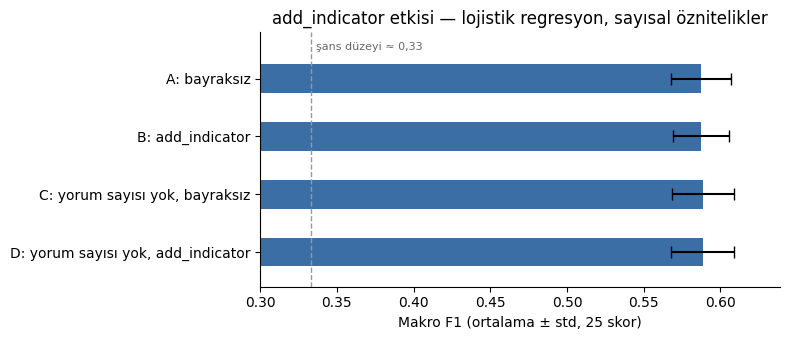

Açıklama: A–B ve C–D çiftleri yalnızca 'eksikti' bayrağının varlığıyla ayrışıyor.


In [22]:
# =====================================================================
# 1.3-d — add_indicator deneyi: "eksikti" bayrağı modele bir şey katıyor mu?
# 1.3-c hücresinden sonra yeni bir hücreye yapıştırın (df13 hazırken).
# =====================================================================
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

# ---- 1) Modelleme verisi (ORTAK_KARARLAR: kısa dönem + fiyatı olanlar) ----
fiyat = df13["price"].str.replace(r"[$,]", "", regex=True).astype(float)   # "$4,736.32" -> 4736.32
veri  = df13[(df13["minimum_nights"] < 30) & fiyat.notna()].copy()
fiyat = fiyat[veri.index]

# Hedef: sabit sınırlarla üç dilim (ORTAK_KARARLAR, karar 4)
y = pd.cut(fiyat, [-np.inf, 3455.50, 5877.67, np.inf], right=False,
           labels=["ucuz", "orta", "pahali"]).astype(str)
gruplar = veri["host_id"]                       # bölme ev sahibine göre
print("Satır:", len(veri), "| Sınıflar:", y.value_counts().to_dict())

# ---- 2) Öznitelikler: şimdilik yalnız sayısal adaylar (kategorikler 1.4'te) ----
sayisal_oznitelikler = [
    "accommodates", "bedrooms", "beds", "latitude", "longitude",
    "minimum_nights", "maximum_nights",
    "availability_30", "availability_60", "availability_90", "availability_365",
    "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
    "review_scores_checkin", "review_scores_communication",
    "review_scores_location", "review_scores_value",
    "host_listings_count", "calculated_host_listings_count", "hosts_time_as_host_years",
]
X = veri[sayisal_oznitelikler]
print("Eksik içeren öznitelik sayısı:", int((X.isna().mean() > 0).sum()))

# ---- 3) İki hat: tek fark add_indicator ----
#   Pipeline = adımları sırayla bağlayan zincir. cross_val_score her katta
#   zinciri YALNIZ eğitim verisiyle kurar (medyan da eğitim verisinden hesaplanır)
#   -> sızıntı yok. 1.5'te bunun neden önemli olduğunu deneyle göreceğiz.
def hat(add_indicator):
    return Pipeline([
        ("doldur",  SimpleImputer(strategy="median", add_indicator=add_indicator)),
        ("olcekle", StandardScaler()),
        ("model",   LogisticRegression(max_iter=2000)),
    ])

# ---- 4) Değerlendirme: ev sahibine göre 5 kat x 5 tekrar = 25 skor ----
def skorla(model, X):
    skorlar = []
    for tohum in range(5):                       # 5 farklı karıştırma = tekrarlı ÇD
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=tohum)
        skorlar.extend(cross_val_score(model, X, y, groups=gruplar, cv=cv,
                                       scoring="f1_macro"))
    return np.array(skorlar)

sonuc = {}
sonuc["A: bayraksız"]     = skorla(hat(False), X)
sonuc["B: add_indicator"] = skorla(hat(True),  X)

# ---- 5) Yan deney: yorum sayısı sütunları OLMADAN ----
#   Puanın eksik olduğunu model zaten number_of_reviews = 0'dan anlayabilir.
#   Bu sütunları çıkarırsak bayrağın tek başına katkısını görürüz.
X_yorumsuz = X.drop(columns=["number_of_reviews", "number_of_reviews_ltm", "reviews_per_month"])
sonuc["C: yorum sayısı yok, bayraksız"]     = skorla(hat(False), X_yorumsuz)
sonuc["D: yorum sayısı yok, add_indicator"] = skorla(hat(True),  X_yorumsuz)

tablo = pd.DataFrame({k: {"ortalama": v.mean(), "std": v.std()} for k, v in sonuc.items()}).T.round(4)
print("\nMakro F1 (ev sahibine göre 5x5 çapraz doğrulama):")
print(tablo.to_string())

# ---- 6) Grafik: hata çubuklarıyla (yönerge 3.4: ortalama ± std) ----
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(tablo.index[::-1], tablo["ortalama"][::-1], xerr=tablo["std"][::-1],
        color="#3b6ea5", height=0.5, capsize=4)
ax.set_xlabel("Makro F1 (ortalama ± std, 25 skor)")
ax.set_xlim(0.30, max(0.60, tablo["ortalama"].max() + 0.05))
ax.axvline(1/3, color="#999999", linestyle="--", linewidth=1)
ax.set_ylim(-0.6, len(tablo) - 0.2)
ax.text(1/3 + 0.003, len(tablo) - 0.45, "şans düzeyi ≈ 0,33", color="#666666", fontsize=8, va="center")
ax.set_title("add_indicator etkisi — lojistik regresyon, sayısal öznitelikler")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print("Açıklama: A–B ve C–D çiftleri yalnızca 'eksikti' bayrağının varlığıyla ayrışıyor.")

Ne bulduk: Puan sütunlarında add_indicator ile “eksikti” bayrağı eklemek lojistik regresyonun makro F1 skorunu değiştirmedi (0,5874 ± 0,019 → 0,5874 ± 0,019; ev sahibine göre 5×5 çapraz doğrulama). Yorum sayısı sütunları çıkarıldığında da bayrak katkı sağlamadı (0,5889 → 0,5884).

Ne anlama geliyor: 1.3-c’de puan eksikliğinin tamamen number_of_reviews = 0 ile açıklandığını bulmuştuk (MAR); bayrak, modelin zaten gördüğü bir bilgiyi tekrarlıyor. Yorum sayısı olmadan da etki yok: puanı eksik ilanlarda pahalı dilim oranı %39'a karşı %32, ilişki doğrusal bir model için zayıf.

Neyi söyleyemeyiz: Sonuç lojistik regresyon ve medyanla doldurma için geçerli; ağaç modelleri bayrağı farklı kullanabilir (Bölüm 2'de yeniden bakılacak). Ayrıca scikit-learn 1.6.1 ile 1.9.1 arasında StratifiedGroupKFold farklı katlar ürettiği için skorlar ±0,002 kayabiliyor; hüküm iki sürümde de aynı.

In [23]:
# ===== WEKA-1 — Weka'nın açabileceği bir CSV hazırlama =====
weka = df13.copy()

# 1) Weka'yı çökerten sütunlar:
#    - uzun metin ve listeler: içinde "" kaçışı, virgül, satır sonu var ("Index 90 out of bounds")
#    - URL'ler: her satırda farklı; Weka ilk 100 satırdan öğrenip 101.'de çöküyor
#    - kişi/ilan adları: içlerinde kesme işareti (') var, Weka onu tırnak sanıyor
cokertenler = ["description", "host_about", "amenities", "price_quote_raw",
               "name", "host_name"] + [c for c in weka.columns if c.endswith("_url")]
weka = weka.drop(columns=cokertenler)

# 2) Kalan metinlerdeki kesme işaretlerini temizle (ör. host_location'da 2 kayıt)
for c in weka.columns:
    if not pd.api.types.is_numeric_dtype(weka[c]):
        weka[c] = weka[c].str.replace("'", "", regex=False)

# 3) Fiyatı sayıya çevir: "$4,736.32" -> 4736.32 (yoksa Weka 13.000 değerli bir kategori sanar)
weka["price"] = weka["price"].str.replace(r"[$,]", "", regex=True).astype(float)

weka.to_csv("weka_adim1.csv", index=False)
print("Kaydedildi: weka_adim1.csv |", weka.shape[0], "satır,", weka.shape[1], "sütun")

# Colab'dan bilgisayarına indir
from google.colab import files
files.download("weka_adim1.csv")

Kaydedildi: weka_adim1.csv | 27232 satır, 78 sütun


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 1.4 Kategorik kodlama
Yüksek kardinaliteli bir sütunda bire-bir, nadir kategorileri birleştiren bire-bir ve kat dışı hedef kodlama; hedef kodlamanın bir kez yanlış uygulanması.

property_type  farklı değer:    66 | 10'dan az ilanı olan:    36 | tek ilanlık:    15
license        farklı değer:  4770 | 10'dan az ilanı olan:  4546 | tek ilanlık:  2626

Makro F1 (lojistik regresyon, ev sahibine göre 5x5 ÇD):
                                                  ortalama     std
sütun         kodlama                                             
—             kategorik yok (taban)                 0.5874  0.0185
property_type bire-bir                              0.5888  0.0194
              bire-bir + nadir birleştir            0.5906  0.0196
              kat dışı hedef kodlama                0.5901  0.0203
              YANLIŞ: hedef kodlama bütün veride    0.5940  0.0196
license       bire-bir                              0.5758  0.0232
              bire-bir + nadir birleştir            0.5951  0.0173
              kat dışı hedef kodlama                0.5900  0.0173
              YANLIŞ: hedef kodlama bütün veride    0.8084  0.0122


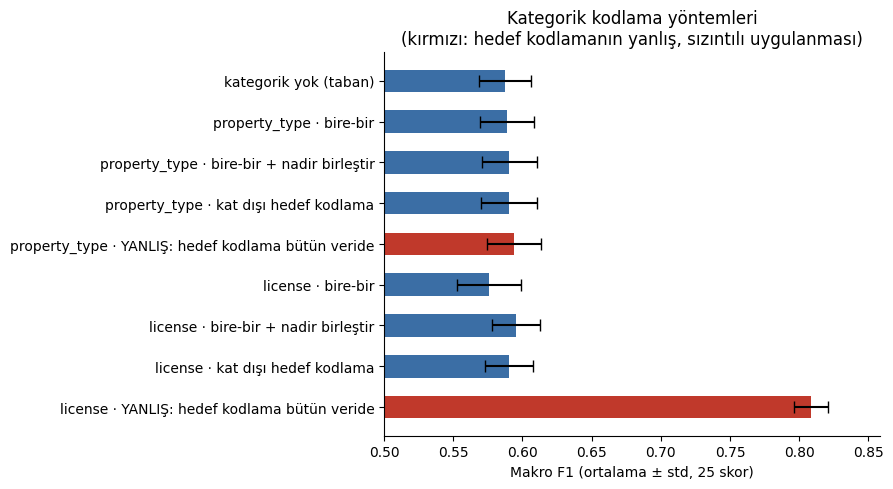

Açıklama: Mavi çubuklar sızıntısız hatlar; kırmızı çubuk, hedef kodlama oranları test etiketleri de dahil bütün veriden hesaplandığında elde edilen (geçersiz) skor.


In [25]:
# =====================================================================
# 1.4 — Kategorik kodlama: bire-bir, nadirleri birleştiren bire-bir,
#        kat dışı hedef kodlama ve hedef kodlamanın YANLIŞ uygulanması
# 1.3-d hücresinden sonra çalıştırın (veri, y, gruplar, sayisal_oznitelikler,
# skorla() hazır olmalı).
# Süre: Colab'da yaklaşık 10–15 dakika (license için bire-bir kodlama yavaş).
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.linear_model import LogisticRegression
import warnings
from sklearn.exceptions import ConvergenceWarning
# license için bire-bir kodlama binlerce sütun üretir; lojistik regresyon bazı katlarda
# yakınsama uyarısı verir. Sonucu değiştirmediği için uyarıları gizliyoruz (yorumda not edilmeli).
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ---- 0) Hangi sütunlar? ----
# property_type: 66 kategori, 36'sında 10'dan az ilan var -> "nadir kategori" sorununun tipik örneği
# license     : binlerce farklı değer -> gerçekten yüksek kardinaliteli; hedef kodlama sızıntısını en net gösteren sütun
for c in ["property_type", "license"]:
    sayilar = veri[c].fillna("YOK").value_counts()
    print(f"{c:<14} farklı değer: {len(sayilar):>5} | 10'dan az ilanı olan: {(sayilar < 10).sum():>5} "
          f"| tek ilanlık: {(sayilar == 1).sum():>5}")

# Kategorik sütunlardaki boşları "YOK" adlı bir kategori yapıyoruz (eksik de bir bilgi)
for c in ["property_type", "license"]:
    veri[c] = veri[c].fillna("YOK")

# ---- 1) Hat kurucu: sayısal kısım hep aynı, sadece kategorik kodlayıcı değişiyor ----
sayisal_hat = Pipeline([
    ("doldur",  SimpleImputer(strategy="median", add_indicator=True)),
    ("olcekle", StandardScaler()),
])

def hat_kur(kodlayici, kategorik_sutun):
    adimlar = [("sayisal", sayisal_hat, sayisal_oznitelikler)]
    if kodlayici is not None:
        # hedef kodlamanın çıktısı da ölçeklensin diye kodlayıcıyı bir mini hatta koyuyoruz
        adimlar.append(("kategorik",
                        Pipeline([("kodla", kodlayici), ("olcekle", StandardScaler(with_mean=False))]),
                        [kategorik_sutun]))
    return Pipeline([
        ("hazirla", ColumnTransformer(adimlar)),
        ("model",   LogisticRegression(max_iter=3000)),
    ])

# ---- 2) Dört kodlama yöntemi ----
def kodlayicilar():
    return {
        # a) Bire-bir (one-hot): her kategori ayrı bir 0/1 sütunu
        "bire-bir":                  OneHotEncoder(handle_unknown="ignore"),
        # b) Nadirleri birleştiren bire-bir: eğitim verisinde 30'dan az görülen kategoriler "diğer" olur
        "bire-bir + nadir birleştir": OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30),
        # c) Kat dışı hedef kodlama: kategoriyi, o kategorideki sınıf oranlarıyla temsil eder.
        #    TargetEncoder eğitim verisinin İÇİNDE de çapraz doğrulama yapar (kat dışı / out-of-fold),
        #    böylece bir ilan kendi etiketini "göremez".
        "kat dışı hedef kodlama":     TargetEncoder(target_type="multiclass", random_state=42),
    }

# ---- 3) YANLIŞ hedef kodlama: oranları BÜTÜN veriden (test dahil) hesaplamak ----
def yanlis_hedef_kodlama(kategorik_sutun):
    """Her kategori için ucuz/orta/pahalı oranlarını tüm 16.558 ilandan hesaplar.
    Test katındaki ilanların etiketleri de bu oranlara girer -> sızıntı."""
    oranlar = pd.crosstab(veri[kategorik_sutun], y, normalize="index")      # kategori x sınıf oranı
    kodlu = oranlar.reindex(veri[kategorik_sutun]).to_numpy()
    X_yanlis = veri[sayisal_oznitelikler].copy()
    for i, sinif in enumerate(oranlar.columns):
        X_yanlis[f"te_{sinif}"] = kodlu[:, i]
    return X_yanlis

# ---- 4) Deney ----
sonuclar = {}
X_tum = veri[sayisal_oznitelikler + ["property_type", "license"]]
sonuclar[("—", "kategorik yok (taban)")] = skorla(hat_kur(None, None), X_tum)

for sutun in ["property_type", "license"]:
    for ad, kodlayici in kodlayicilar().items():
        sonuclar[(sutun, ad)] = skorla(hat_kur(kodlayici, sutun), X_tum)
    # yanlış uygulama: hedef kodlanmış sütunlar zaten "sayısal" hale geldi
    X_yanlis = yanlis_hedef_kodlama(sutun)
    yanlis_hat = Pipeline([("doldur", SimpleImputer(strategy="median", add_indicator=True)),
                           ("olcekle", StandardScaler()),
                           ("model", LogisticRegression(max_iter=3000))])
    sonuclar[(sutun, "YANLIŞ: hedef kodlama bütün veride")] = skorla(yanlis_hat, X_yanlis)

tablo14 = pd.DataFrame({k: {"ortalama": v.mean(), "std": v.std()} for k, v in sonuclar.items()}).T.round(4)
tablo14.index.names = ["sütun", "kodlama"]
print("\nMakro F1 (lojistik regresyon, ev sahibine göre 5x5 ÇD):")
print(tablo14.to_string())

# ---- 5) Grafik ----
import matplotlib.pyplot as plt
etiketler = [f"{s} · {k}" if s != "—" else k for s, k in tablo14.index]
renkler = ["#c0392b" if "YANLIŞ" in k else "#3b6ea5" for _, k in tablo14.index]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiketler[::-1], tablo14["ortalama"][::-1], xerr=tablo14["std"][::-1],
        color=renkler[::-1], height=0.55, capsize=4)
ax.set_xlabel("Makro F1 (ortalama ± std, 25 skor)")
ax.set_xlim(0.50, min(1.0, tablo14["ortalama"].max() + 0.05))
ax.set_title("Kategorik kodlama yöntemleri\n(kırmızı: hedef kodlamanın yanlış, sızıntılı uygulanması)")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print("Açıklama: Mavi çubuklar sızıntısız hatlar; kırmızı çubuk, hedef kodlama oranları test "
      "etiketleri de dahil bütün veriden hesaplandığında elde edilen (geçersiz) skor.")

**Yorum** Lisans numaralarının yarısından fazlası tek bir ilana ait olduğu için, hedef kodlamayı bütün veride yapmak her ilana kendi cevabını öznitelik olarak verdi ve skoru 0,59'dan 0,81'e sahte biçimde yükseltti; doğru yöntem kodlamayı her katta yalnız eğitim verisiyle, kat dışı yapmaktır.
…

### 1.5 Sızıntı deneyi
Ön işlemenin bütün veride yapıldığı kurulum (yanlış) ile `Pipeline` içinde yapıldığı kurulum (doğru); hata çubuklarıyla.

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

Makro F1 (5x5 çapraz doğrulama):
                                                                     ortalama     std  fark (doğruya göre)
model              kurulum                                                                                
Lojistik regresyon DOĞRU: Pipeline + ev sahibine göre bölme            0.5874  0.0185               0.0000
                   YANLIŞ-1: ön işleme bütün veride                    0.5872  0.0183              -0.0002
                   YANLIŞ-2: rastgele bölme (ev sahibi yok sayıldı)    0.6006  0.0075               0.0132
Karar ağacı        DOĞRU: Pipeline + ev sahibine göre bölme            0.5445  0.0156               0.0000
                   YANLIŞ-1: ön işleme bütün veride                    0.5447  0.0138               0.0002
                   YANLIŞ-2: rastgele bölme (ev sahibi yok sayıldı)    0.6407  0.0076               0.0962


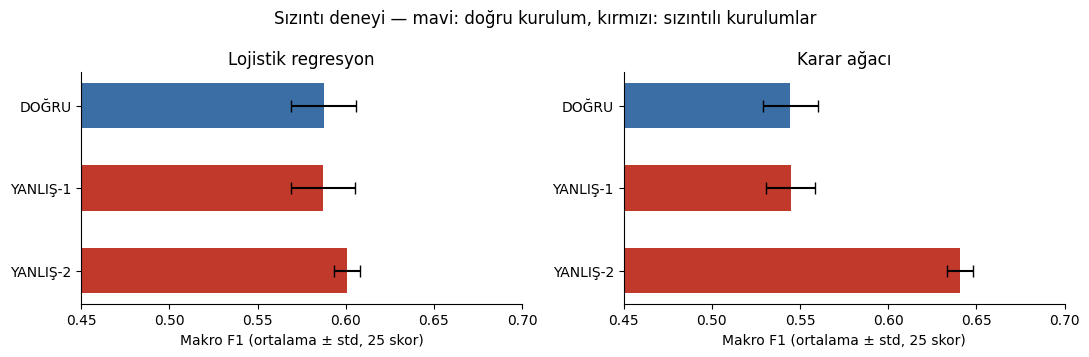

Açıklama: YANLIŞ-1 = medyan ve ölçek bütün veriden öğrenildi; YANLIŞ-2 = aynı ev sahibinin ilanları hem eğitimde hem testte.


In [27]:
# =====================================================================
# 1.5 — Sızıntı deneyi: ön işleme bütün veride mi, Pipeline içinde mi?
# 1.3-d hücresinden sonra çalıştırın (veri, y, gruplar, sayisal_oznitelikler hazır olmalı).
# Ek olarak ikinci bir sızıntı türünü de ölçüyoruz: bölmede ev sahibini yok saymak.
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score

X = veri[sayisal_oznitelikler]

# ---- Değerlendirme: 5 kat x 5 tekrar; bölme türü seçilebilir ----
def skorla_cv(model, X, gruba_gore=True):
    skorlar = []
    for tohum in range(5):
        if gruba_gore:   # DOĞRU: aynı ev sahibinin ilanları hep aynı katta
            cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=tohum)
            s = cross_val_score(model, X, y, groups=gruplar, cv=cv, scoring="f1_macro")
        else:            # YANLIŞ: ev sahibi yok sayılır, ilanlar rastgele dağıtılır
            cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=tohum)
            s = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")
        skorlar.extend(s)
    return np.array(skorlar)

# ---- İki model: biri doğrusal, biri ezberlemeye yatkın ----
modeller = {
    "Lojistik regresyon": lambda: LogisticRegression(max_iter=2000),
    "Karar ağacı":        lambda: DecisionTreeClassifier(min_samples_leaf=5, random_state=42),
}

sonuclar = {}
for model_adi, yeni_model in modeller.items():

    # (1) DOĞRU: ön işleme Pipeline içinde -> her katta medyan ve ölçek YALNIZ eğitim verisinden
    dogru_hat = Pipeline([
        ("doldur",  SimpleImputer(strategy="median", add_indicator=True)),
        ("olcekle", StandardScaler()),
        ("model",   yeni_model()),
    ])

    # (2) YANLIŞ: ön işleme BÜTÜN veride (test katları dahil) bir kez yapılıyor,
    #     model sonra bu "önceden hazırlanmış" veride çapraz doğrulanıyor
    X_on_islenmis = StandardScaler().fit_transform(
        SimpleImputer(strategy="median", add_indicator=True).fit_transform(X))

    sonuclar[(model_adi, "DOĞRU: Pipeline + ev sahibine göre bölme")] = skorla_cv(dogru_hat, X, True)
    sonuclar[(model_adi, "YANLIŞ-1: ön işleme bütün veride")]         = skorla_cv(yeni_model(), X_on_islenmis, True)
    sonuclar[(model_adi, "YANLIŞ-2: rastgele bölme (ev sahibi yok sayıldı)")] = skorla_cv(dogru_hat, X, False)

tablo15 = pd.DataFrame({k: {"ortalama": v.mean(), "std": v.std()} for k, v in sonuclar.items()}).T.round(4)
tablo15.index.names = ["model", "kurulum"]
# doğru kuruluma göre fark
tablo15["fark (doğruya göre)"] = tablo15.groupby(level="model")["ortalama"].transform(
    lambda s: (s - s.iloc[0]).round(4))
print("Makro F1 (5x5 çapraz doğrulama):")
print(tablo15.to_string())

# ---- Grafik: hata çubuklarıyla ----
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, model_adi in zip(axes, modeller):
    t = tablo15.loc[model_adi]
    renk = ["#3b6ea5" if k.startswith("DOĞRU") else "#c0392b" for k in t.index]
    ax.barh(range(len(t))[::-1], t["ortalama"], xerr=t["std"], color=renk, height=0.55, capsize=4)
    ax.set_yticks(range(len(t))[::-1])
    ax.set_yticklabels([k.split(":")[0] for k in t.index])
    ax.set_title(model_adi)
    ax.set_xlabel("Makro F1 (ortalama ± std, 25 skor)")
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
axes[0].set_xlim(0.45, 0.70)
fig.suptitle("Sızıntı deneyi — mavi: doğru kurulum, kırmızı: sızıntılı kurulumlar")
plt.tight_layout(); plt.show()
print("Açıklama: YANLIŞ-1 = medyan ve ölçek bütün veriden öğrenildi; "
      "YANLIŞ-2 = aynı ev sahibinin ilanları hem eğitimde hem testte.")

**Yorum** Ne bulduk: Medyanla doldurma ve ölçeklemeyi bütün veride yapmak, Pipeline içinde yapmaya göre skoru değiştirmedi (lojistik regresyon 0,5874 → 0,5872; karar ağacı 0,5445 → 0,5447). Buna karşılık bölmede ev sahibini yok saymak skoru belirgin şişirdi: lojistik regresyonda +0,013, karar ağacında +0,096 (0,545 → 0,641).

Ne anlama geliyor: Ön işleme sızıntısının etkisi, sızan istatistiğin hedefle ilişkisine ve veri boyutuna bağlıdır. Medyan ve ölçek fiyat bilgisi taşımadığı ve 16.558 satırda kararlı olduğu için etki ihmal edilebilir; hedef kodlamada (1.4) ise +0,22 idi. Bu veride asıl risk varlık düzeyinde: aynı ev sahibinin benzer ilanları eğitim ve teste dağılınca ezberlemeye yatkın modeller ödüllendiriliyor. Rastgele bölmede karar ağacı lojistik regresyondan iyi görünürken (0,641'e karşı 0,601), doğru bölmede sıralama tersine dönüyor (0,545'e karşı 0,587). Yani sızıntı yalnız skoru değil, model seçimini de bozuyor (Kaufman vd., 2012).

Neyi söyleyemeyiz: Ön işleme sızıntısının küçük çıkması bu veri boyutu ve bu adımlar içindir; küçük verilerde ya da hedefe dayalı adımlarda sonuç farklı olur. Ev sahibine göre bölme, aynı binadaki farklı ev sahipleri gibi diğer olası bağımlılıkları dışlamaz.

### 1.6 Baseline ve ilk model
`DummyClassifier` ve tek bir basit model, sızıntısız hat içinde.

In [ ]:
from sklearn.dummy import DummyClassifier

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.7 Weka ile bağımsız kontrol
ZeroR ve J48, 10 kat çapraz doğrulama; çıktıyı yapıştırın ve Python ile tutarlılığını yorumlayın.

In [ ]:
weka_cikti = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** …

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe ÇD skorunun karşılaştırması.

In [ ]:
from sklearn.model_selection import GridSearchCV

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [ ]:
# import joblib
# df_temiz.to_csv("p1_temiz_veri.csv", index=False)
# joblib.dump(hat, "p1_hat.joblib")

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** …

### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek:** …

In [ ]:
!pip -q install mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [ ]:
weka_apriori = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi *(4 ve 5 kişilik gruplar)*

### E1.1 Budama eğrisi
Karar ağacında `ccp_alpha` taraması; ağaç boyutu ile eğitim ve test başarımı aynı grafikte.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.2 Doyum eğrisi
Rastgele ormanda ağaç sayısı 1–500; OOB ve test hatası.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.3 Öznitelik önemi
Rastgele bir sütun ekleyin; Gini önemi ve permütasyon önemi sıralamalarını karşılaştırın.

In [ ]:
from sklearn.inspection import permutation_importance

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 2 · Öznitelik seçimi ve kararlılığı *(5 kişilik gruplar)*
**Makale:** Meinshausen ve Bühlmann (2010). Stability selection. *JRSS B*, 72(4).

**Okuma notu (3–4 cümle):** …

### E2.1 Üç aile
Filtre, sarmalayıcı ve gömülü birer yöntem, hattın içinde.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.2 Kararlılık
100 farklı %70'lik alt örneklemde seçimi tekrarlayın; seçilme oranlarını çizin.

In [ ]:
from collections import Counter

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.3 Seçimin katkısı
Seçimli ve seçimsiz hattın dürüst karşılaştırması.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

## Varsayım defteri
Bu ödevde verdiğiniz her kararı ve gerekçesini madde madde yazın (ön işleme, ölçüt, eşik, parametre, veri seçimi). En az bir kararın ödev makalesine dayandığını belirtin.

- **Karar:** … — **Gerekçe:** …
- **Karar:** … — **Gerekçe:** …

## Katkı beyanı (zorunlu)
Her üyenin hangi alt başlıklarda (ör. 1.3, 2.4) ve hangi işlerde (kod, analiz, yorum, sunum hazırlığı) çalıştığını somut olarak yazın. Katkı puanı bu beyana göre verilir: somutluk %30, pay %30, GitHub commit geçmişiyle tutarlılık %25, sunumla tutarlılık %15.

| Üye | Çalıştığı alt başlıklar ve işler | Sunumda anlattığı alt başlık |
|---|---|---|
| Üye 1 | | |
| Üye 2 *(varsa)* | | |
| Üye 3 *(varsa)* | | |
| Üye 4 *(varsa)* | | |
| Üye 5 *(varsa)* | | |

## Yapay zekâ beyanı
Yapay zekâ araçları kullandıysanız hangi aşamada ve ne için kullandığınızı yazın. Kullanmadıysanız "Kullanılmadı" yazın.

…

## Kaynaklar
- …